In [30]:
import geopandas as gpd
import pandas as pd
import sys
import numpy as np

from pathlib import Path

locations = ['Blk_Air_7', 'Blk_Air_2', 'Blk_Air_32', 'Blk_Air_17', 'Blk_Air_42'] #60-70 42,7, 32, 65, 2 and 70-80 65,7,32,2
# make the shared code in src/ importable even when the package is not pip-installed

legend_labels = {
    "Blk_Air_23": "Luxor (CU 23; 100% of women unpaid)",
    "Blk_Air_18": "Gharbia (CU 18; 69% of women unpaid)",
    "Blk_Air_42": "Ismailiya (42 63; 39% of women unpaid)",
    'Blk_Air_51':"Damietta (CU 51; 26% of women unpaid)",
    "Blk_Air_7": "Suhag (CU 7; 100% of women unpaid)",
    "Blk_Air_2": "Behera (CU 2; 86% of women unpaid)",
    "Blk_Air_65": "Menia (CU 65; 73% of women unpaid)",
    "Blk_Air_32": "Gharbia (CU 32; 69% of women unpaid)",
    "Blk_Air_17": "Dakahlia (CU 17; 57% of women unpaid)",
}


REPO_ROOT = Path.cwd().parent.parent
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

In [31]:

src_dir = r"c:\Users\hermawan\OneDrive - Stichting Deltares\PhD\Egypt_ERF_data\Data\map"
excel_path = r"c:\Users\hermawan\OneDrive - Stichting Deltares\PhD\Egypt_ERF_data\Data\data_correlation.xlsx"

In [32]:
wage_df = pd.read_csv(REPO_ROOT / 'Results/wage_by_command_unit.csv')
productivity_df = pd.read_csv(REPO_ROOT / 'Results/group_productivity.csv', index_col=0)

In [33]:
map_df = wage_df.merge(productivity_df, on='area', how='left')

In [34]:
command_gdf = gpd.read_file(src_dir + '\Final2_Command_Area.shp')
conversion_df = pd.read_excel(excel_path, sheet_name='command_area')

mapping = conversion_df.merge(
    command_gdf[['Name', 'OBJECTID', 'geometry']],
    left_on = 'area_map_name',
    right_on = 'OBJECTID',
).set_index('area_name')["Name"]

# mapping = (
#     command_gdf.merge(
#         conversion_df[['area_map_name', 'area_name']],
#         left_on='OBJECTID',
#         right_on='area_map_name'
#     )
#     .set_index('Name')['area_map_name']
# )

# excel_salinity_df['area'] = excel_salinity_df['area'].map(mapping)

<>:1: SyntaxWarning: invalid escape sequence '\F'
<>:1: SyntaxWarning: invalid escape sequence '\F'
C:\Users\hermawan\AppData\Local\Temp\ipykernel_26164\176042714.py:1: SyntaxWarning: invalid escape sequence '\F'
  command_gdf = gpd.read_file(src_dir + '\Final2_Command_Area.shp')


In [35]:
map_df['area_name'] = map_df['area'].map(mapping)
map_df['geometry'] = map_df['area_name'].map(command_gdf.set_index('Name')['geometry'])
map_gdf = gpd.GeoDataFrame(map_df, geometry='geometry')
#map_gdf

In [36]:
command_gdf['area'] = command_gdf["Name"].map(mapping)
#command_gdf

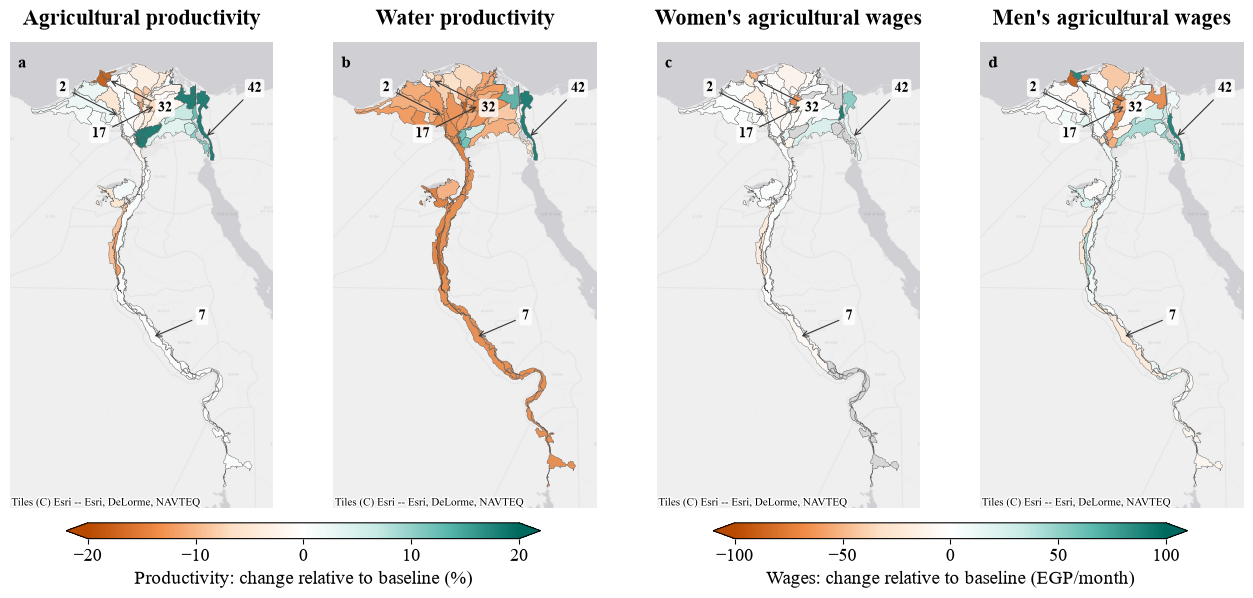

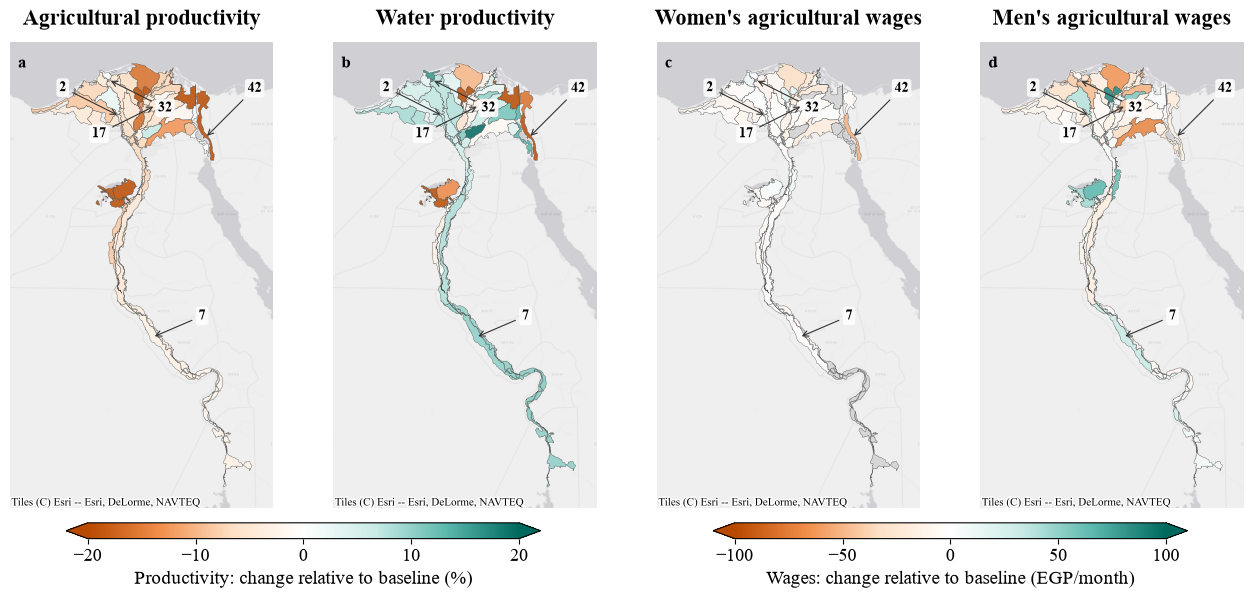

In [37]:
import contextily as cx
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable

label_column = 'area'
# Offsets follow the order of your existing locations list
label_offsets = [(35, 15), (-40, 20), (40, -20), (-40, -20), (35, 35), (-35, -35)]
FIGURE_DIR = REPO_ROOT / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
baseline, scenarios = '70', ['60', '80']


panels = [('agricultural_productivity', 'Agricultural productivity', 'productivity'), ('water_productivity', 'Water productivity', 'productivity'), ('female', "Women's agricultural wages", 'wages'), ('male', "Men's agricultural wages", 'wages')]
vlims = {'productivity': 20, 'wages': 100}
cbar_labels = {'productivity': f'Productivity: change relative to baseline (%)', 'wages': f'Wages: change relative to baseline (EGP/month)'}
cmap = LinearSegmentedColormap.from_list('orange_teal', ['#b84a00', '#f28e4b', '#fde0c5', '#ffffff', '#c9ebe6', '#5bb8ad', '#00695f'])
norms = {group: Normalize(vmin=-v, vmax=v) for group, v in vlims.items()}

for scenario in scenarios:
    plot_gdf = map_gdf.to_crs(epsg=3857).copy()
    for var, _, group in panels:
        base = plot_gdf[f'{var}_{baseline}']
        diff = plot_gdf[f'{var}_{scenario}'] - base
        plot_gdf[f'{var}_diff'] = diff / base.where(base != 0) * 100 if group == 'productivity' else diff

    selected = plot_gdf.loc[plot_gdf[label_column].isin(locations), [label_column, plot_gdf.geometry.name]]
    label_points = selected.dissolve(by=label_column).geometry.representative_point().to_dict() if not selected.empty else {}

    minx, miny, maxx, maxy = plot_gdf.total_bounds
    pad = 0.05 * max(maxx - minx, maxy - miny)
    fig, axes = plt.subplots(1, 4, figsize=(16, 6.5), sharex=True, sharey=True)

    for ax, (var, title, group), letter in zip(axes, panels, 'abcd'):
        ax.set_xlim(minx - pad, maxx + pad)
        ax.set_ylim(miny - pad, maxy + pad)
        plot_gdf.plot(column=f'{var}_diff', ax=ax, cmap=cmap, norm=norms[group], alpha=0.85, edgecolor='0.3', linewidth=0.3, missing_kwds={'color': 'lightgrey', 'edgecolor': '0.3', 'linewidth': 0.3})
        cx.add_basemap(ax, source=cx.providers.Esri.WorldGrayCanvas, crs=plot_gdf.crs, zoom=8)

        for i, name in enumerate(locations):
            point = label_points.get(name)
            if point is not None and not point.is_empty:
                offset = label_offsets[i % len(label_offsets)]
                ax.annotate(name.split('_')[-1], xy=(point.x, point.y), xytext=offset, textcoords='offset points', ha='center', va='center', fontsize=10, fontweight='bold', color='black', bbox={'boxstyle': 'round,pad=0.2', 'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.85}, arrowprops={'arrowstyle': '->', 'color': '0.2', 'lw': 0.8, 'shrinkA': 3, 'shrinkB': 1}, zorder=10)

        ax.set_title(title, fontweight='bold', y=1.02, pad=6)
        ax.text(0.03, 0.97, letter, transform=ax.transAxes, va='top', fontweight='bold', fontsize=12)
        ax.set_axis_off()

    for group, group_axes in [('productivity', axes[:2]), ('wages', axes[2:])]:
        v = vlims[group]
        cbar = fig.colorbar(ScalarMappable(norm=norms[group], cmap=cmap), ax=list(group_axes), orientation='horizontal', fraction=0.04, pad=0.03, aspect=30, shrink=0.8, extend='both')
        cbar.set_label(cbar_labels[group])
        cbar.set_ticks([-v, -v / 2, 0, v / 2, v])

    fig.savefig(FIGURE_DIR / f'map_plots_{baseline}_{scenario}.png', dpi=300, bbox_inches='tight')
    plt.show()

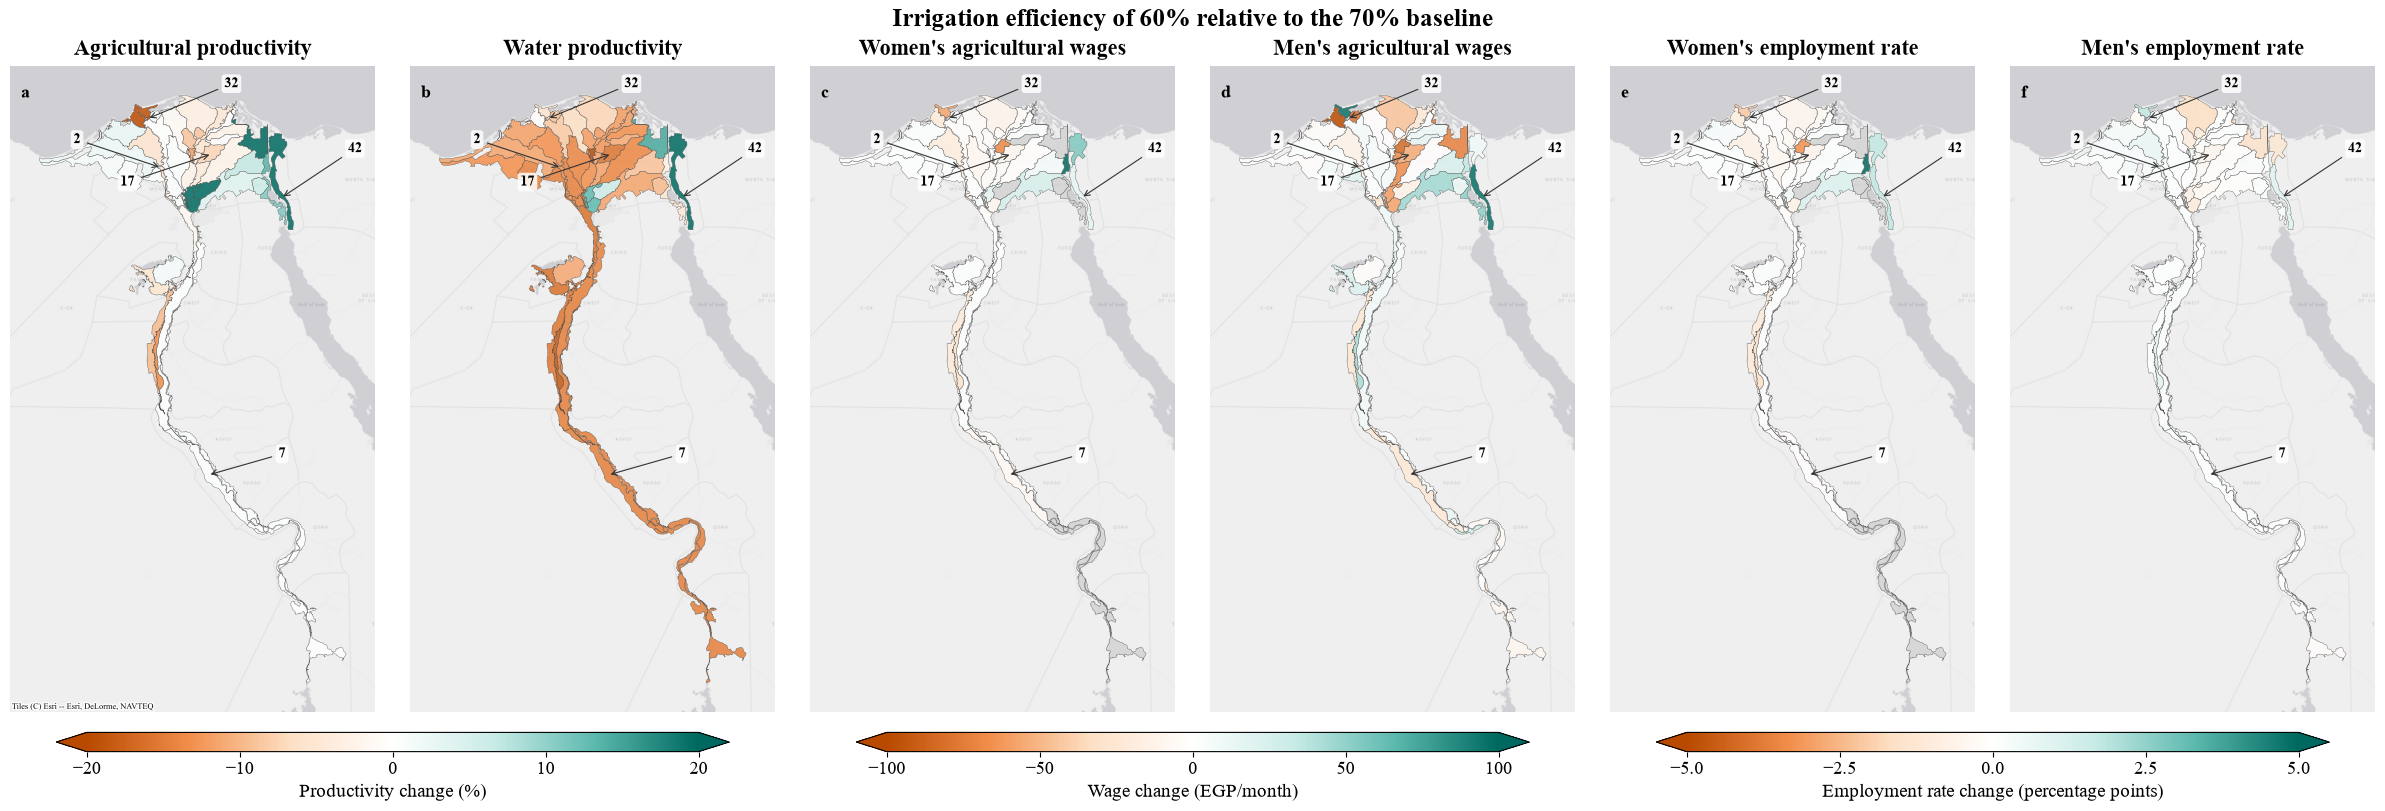

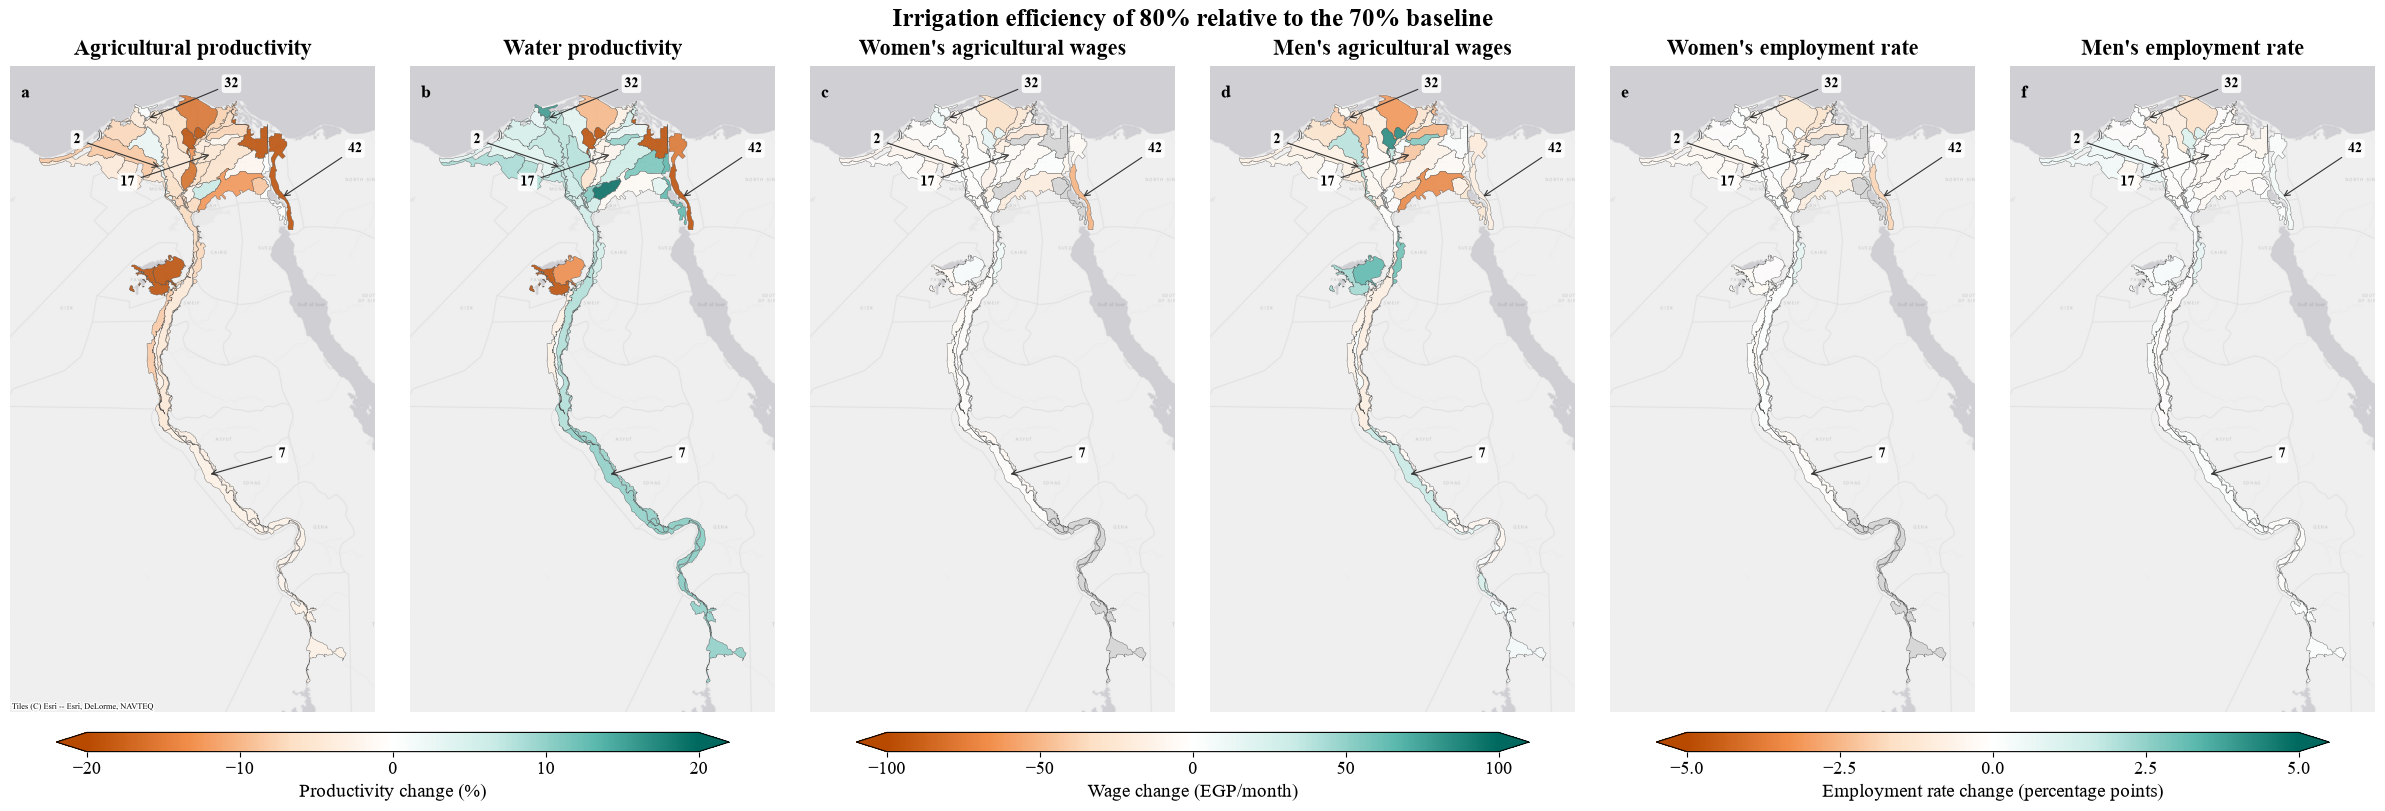

In [38]:
from pathlib import Path
import contextily as cx
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap, Normalize

# Settings
plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman"], "font.size": 14,
                     "axes.titlesize": 16, "axes.labelsize": 14, "xtick.labelsize": 13,
                     "ytick.labelsize": 13, "pdf.fonttype": 42, "ps.fonttype": 42})

baseline, scenarios = "70", ["60", "80"]
label_column = "area"
label_offsets = [(35, 15), (-40, 20), (40, -20), (-40, -20), (35, 35), (-35, -35)]
FIGURE_DIR = REPO_ROOT / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Read the unemployment CSV and calculate employment as 1 - unemployment.
csv_path = Path(r"C:\Users\hermawan\OneDrive - Stichting Deltares\PhD\Egypt_ERF_data\Results\unemployment_rate.csv")
rate_df = pd.read_csv(csv_path, dtype={"scenario": str})
rate_df = rate_df.loc[rate_df["scenario"].isin([baseline, *scenarios])].copy()
rate_df["sex"] = rate_df["sex"].str.strip().str.lower()
pct_above = pd.to_numeric(rate_df["pct_paid"], errors="raise")
if not pct_above.dropna().between(0, 100).all():
    raise ValueError("Expected pct_paid to be a percentage between 0 and 100.")

rate_df["employment_rate"] = pct_above/100
rates = rate_df.pivot(index="area", columns=["scenario", "sex"], values="employment_rate")

# Add women's and men's employment rates to the map for each scenario.
plot_gdf = map_gdf.to_crs(epsg=3857).copy()
for scenario in [baseline, *scenarios]:
    for sex in ["female", "male"]:
        plot_gdf[f"employment_{sex}_{scenario}"] = plot_gdf[label_column].map(rates[(scenario, sex)])

panels = [
    ("agricultural_productivity", "Agricultural productivity", "productivity"),
    ("water_productivity", "Water productivity", "productivity"),  # Original column spelling
    ("female", "Women's agricultural wages", "wages"),
    ("male", "Men's agricultural wages", "wages"),
    ("employment_female", "Women's employment rate", "employment"),
    ("employment_male", "Men's employment rate", "employment"),
]

cmap = LinearSegmentedColormap.from_list("orange_teal", ["#b84a00", "#f28e4b", "#fde0c5", "#ffffff", "#c9ebe6", "#5bb8ad", "#00695f"])
vlims = {"productivity": 20, "wages": 100, "employment": 5}
norms = {group: Normalize(-v, v) for group, v in vlims.items()}
cbar_labels = {"productivity": "Productivity change (%)", "wages": "Wage change (EGP/month)",
               "employment": "Employment rate change (percentage points)"}

# Prepare the same extent, basemap and CU labels for all maps.
selected = plot_gdf.loc[plot_gdf[label_column].isin(locations), [label_column, plot_gdf.geometry.name]]
label_points = selected.dissolve(by=label_column).geometry.representative_point().to_dict() if not selected.empty else {}
minx, miny, maxx, maxy = plot_gdf.total_bounds
pad = 0.05 * max(maxx - minx, maxy - miny)
bounds = (minx - pad, miny - pad, maxx + pad, maxy + pad)
source = cx.providers.Esri.WorldGrayCanvas
basemap, extent = cx.bounds2img(*bounds, zoom=8, source=source)

# Make one figure per scenario, with six panels across and one colour bar per pair.
for scenario in scenarios:
    fig, axes = plt.subplots(1, 6, figsize=(24, 8), sharex=True, sharey=True, layout="constrained")
    fig.suptitle(f"Irrigation efficiency of {scenario}% relative to the {baseline}% baseline", fontsize=18, fontweight="bold")

    for ax, (var, title, group), letter in zip(axes, panels, "abcdef"):
        base = plot_gdf[f"{var}_{baseline}"]
        diff = plot_gdf[f"{var}_{scenario}"] - base
        if group == "productivity":
            diff = 100 * diff / base.where(base != 0)  # Relative change (%)
        elif group == "employment":
            #######VANNIl: check how absolute lkooks like
            diff = 100 * diff                     # Change in percentage points
        plot_gdf[f"{var}_diff"] = diff                 # Wage change is already in EGP/month

        ax.imshow(basemap, extent=extent, interpolation="bilinear", zorder=0)
        ax.set_xlim(bounds[0], bounds[2])
        ax.set_ylim(bounds[1], bounds[3])
        plot_gdf.plot(column=f"{var}_diff", ax=ax, cmap=cmap, norm=norms[group], alpha=0.85,
                      edgecolor="0.3", linewidth=0.3, zorder=2,
                      missing_kwds={"color": "lightgrey", "edgecolor": "0.3", "linewidth": 0.3})

        for i, name in enumerate(locations):
            point = label_points.get(name)
            if point is not None and not point.is_empty:
                dx, dy = label_offsets[i % len(label_offsets)]
                if name == "Blk_Air_32":
                    offset = +45  # Move label 51 straight up
                else:
                    offset = 0
                ax.annotate(name.split("_")[-1], xy=(point.x, point.y), xytext=(1.5 * dx, dy+offset),
                            textcoords="offset points", ha="center", va="center", fontsize=10, fontweight="bold",
                            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85),
                            arrowprops=dict(arrowstyle="->", color="0.2", lw=0.8, shrinkA=3, shrinkB=1), zorder=10)

        ax.set_title(title, fontweight="bold", pad=8)
        ax.text(0.03, 0.97, letter, transform=ax.transAxes, va="top", fontweight="bold", fontsize=13)
        ax.set_axis_off()

    cx.add_attribution(axes[0], source.attribution, font_size=6)
    for group, group_axes in [("productivity", axes[:2]), ("wages", axes[2:4]), ("employment", axes[4:6])]:
        v = vlims[group]
        cbar = fig.colorbar(ScalarMappable(norm=norms[group], cmap=cmap), ax=group_axes.tolist(),
                            orientation="horizontal", fraction=0.045, pad=0.03, shrink=0.85, aspect=35,
                            ticks=[-v, -v / 2, 0, v / 2, v], extend="both")
        cbar.set_label(cbar_labels[group])

    fig.savefig(FIGURE_DIR / f"map_6panels_{scenario}_vs_{baseline}.png", dpi=300, bbox_inches="tight")
    plt.show()

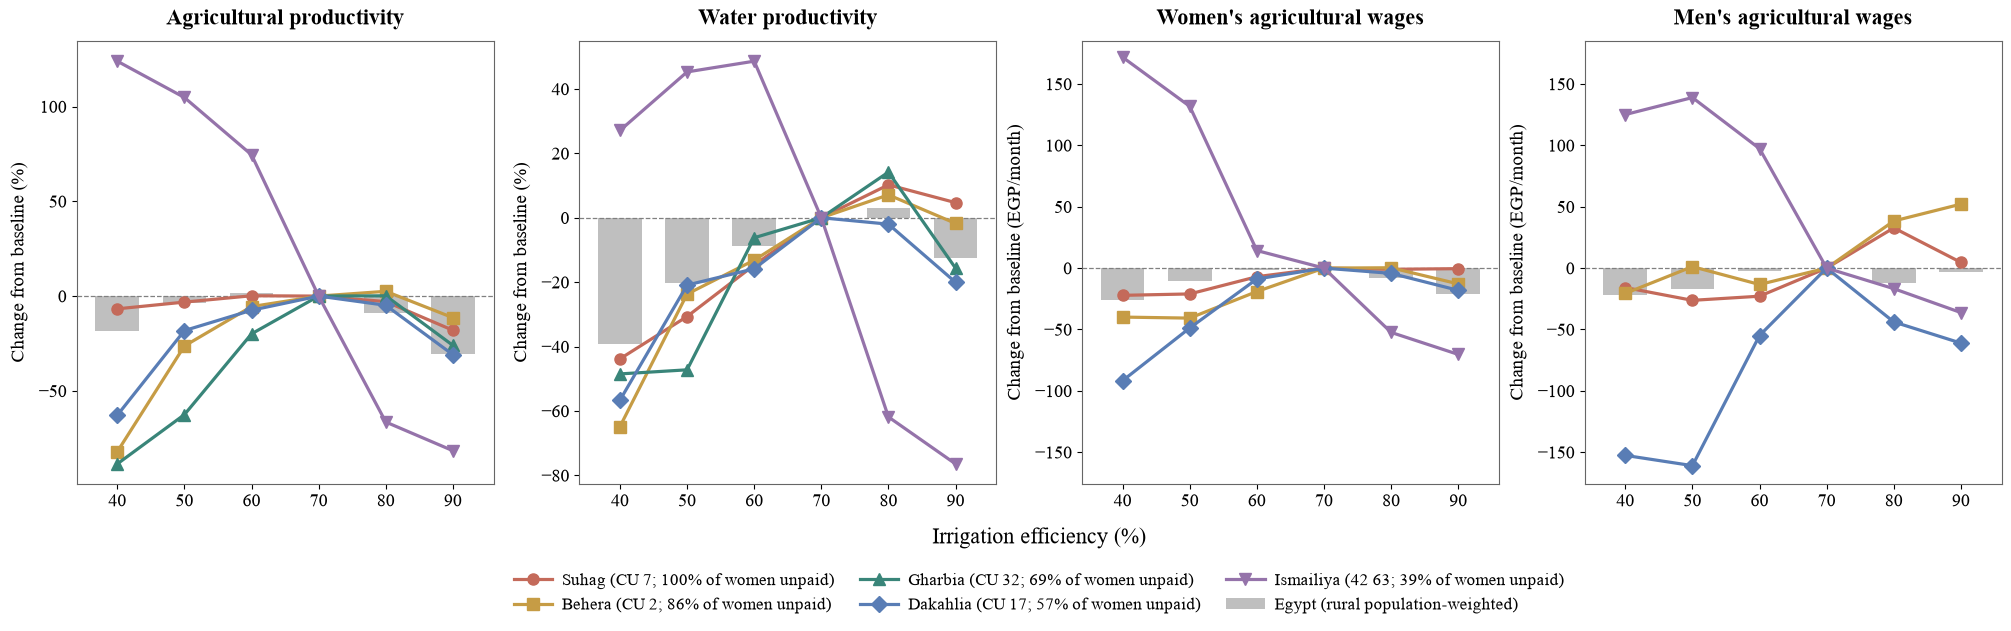

Saved: c:\Users\hermawan\OneDrive - Stichting Deltares\PhD\Egypt_ERF_data\figures\scenario_plot_multiple_locations.png


In [39]:

# Font settings
plt.rcParams.update({
    "font.family": "serif", "font.serif": ["Times New Roman"], "font.size": 14,
    "axes.titlesize": 16, "axes.labelsize": 14, "xtick.labelsize": 13,
    "ytick.labelsize": 13, "legend.fontsize": 12, "pdf.fonttype": 42, "ps.fonttype": 42,
})

# Settings
scenarios = ["40", "50", "60", "70", "80", "90"]
baseline = "70"
location_colors = ["#C46A5A", "#C69C45", "#398579", "#597DB5", "#9573AA", "#6F7645"]
location_markers = ["o", "s", "^", "D", "v", "P"]
location_column = "area"
weight_column = "rural_population"
min_baselines = {"agricultural_productivity": 0, "water_productivity": 0}

FIGURE_DIR = REPO_ROOT / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
panels = [
    ("agricultural_productivity", "Agricultural productivity", "productivity"),
    ("water_productivity", "Water productivity", "productivity"),
    ("female", "Women's agricultural wages", "wages"),
    ("male", "Men's agricultural wages", "wages"),
]

# Validate locations
if not locations:
    raise ValueError("Add at least one location to the locations list.")
rows = {}
for location in locations:
    selected = map_gdf.loc[map_gdf[location_column] == location]
    if len(selected) != 1:
        raise ValueError(f"Expected one row for '{location}', found {len(selected)}. Check map_gdf['{location_column}'].")
    rows[location] = selected.iloc[0]

# Figure: panels, shared x-label, shared legend
x = [int(s) for s in scenarios]
fig = plt.figure(figsize=(20, 6.2), constrained_layout=True)
grid = fig.add_gridspec(3, 4, height_ratios=[4, 0.35, 0.5])
axes = [fig.add_subplot(grid[0, i]) for i in range(4)]
xlabel_ax = fig.add_subplot(grid[1, :])
xlabel_ax.set_axis_off()
xlabel_ax.text(0.5, 0.5, "Irrigation efficiency (%)", ha="center", va="center", fontsize=16, transform=xlabel_ax.transAxes)
legend_ax = fig.add_subplot(grid[2, :])
legend_ax.set_axis_off()

# Background bars: rural population-weighted averages
weights = np.asarray(map_gdf[weight_column], dtype=float)
bar_width = min(np.diff(sorted(x))) * 0.65 if len(x) > 1 else 5

for ax, (var, title, group) in zip(axes, panels):
    baseline_values = np.asarray(map_gdf[f"{var}_{baseline}"], dtype=float)
    scenario_values = np.column_stack([np.asarray(map_gdf[f"{var}_{s}"], dtype=float) for s in scenarios])
    valid = np.isfinite(weights) & (weights > 0) & np.isfinite(baseline_values) & np.all(np.isfinite(scenario_values), axis=1)
    if not valid.any():
        raise ValueError(f"No areas with valid values and positive population for {var}.")
    baseline_mean = np.average(baseline_values[valid], weights=weights[valid])
    scenario_means = np.average(scenario_values[valid], axis=0, weights=weights[valid])
    overall_changes = scenario_means - baseline_mean
    if group == "productivity":
        if baseline_mean == 0 or abs(baseline_mean) < min_baselines[var]:
            overall_changes = np.zeros_like(scenario_means)
        else:
            overall_changes = overall_changes / baseline_mean * 100
    ax.bar(x, overall_changes, width=bar_width, color="#808080", alpha=0.5, edgecolor="none", zorder=1, label="Egypt (rural population-weighted)")

# Selected locations
for i, location in enumerate(locations):
    row = rows[location]
    color = location_colors[i % len(location_colors)]
    marker = location_markers[i % len(location_markers)]
    for ax, (var, title, group) in zip(axes, panels):
        values = np.array([row[f"{var}_{s}"] for s in scenarios], dtype=float)
        baseline_value = float(row[f"{var}_{baseline}"])
        change = values - baseline_value
        if group == "productivity":
            if baseline_value == 0 or abs(baseline_value) < min_baselines[var]:
                change = np.zeros_like(values)
            else:
                change = change / baseline_value * 100
        ax.plot(x, change, marker=marker, markersize=8, linewidth=2.3, color=color, markerfacecolor=color, markeredgecolor=color, markeredgewidth=1, label=legend_labels.get(location, location), zorder=3)

# Format panels
for ax, (_, title, group) in zip(axes, panels):
    ax.axhline(0, color="grey", linestyle="--", linewidth=0.9, zorder=2)
    ax.set_title(title, fontweight="bold", pad=12)
    ax.set_xticks(x)
    ax.set_ylabel("Change from baseline (%)" if group == "productivity" else "Change from baseline (EGP/month)", labelpad=8)
    ax.set_axisbelow(True)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_color("#666666")
        spine.set_linewidth(0.8)

# Same y-axis range for women's and men's wages
ymin = min(axes[2].get_ylim()[0], axes[3].get_ylim()[0])
ymax = max(axes[2].get_ylim()[1], axes[3].get_ylim()[1])
axes[3].sharey(axes[2])
axes[2].set_ylim(ymin, ymax)

# Shared legend on one line
handles, labels = axes[0].get_legend_handles_labels()
legend_ax.legend(handles, labels, loc="center", ncol=3, frameon=False, handlelength=2.3, columnspacing=1.5, handletextpad=0.6)

# Save and show
output_path = FIGURE_DIR / "scenario_plot_multiple_locations.png"
fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {output_path}")

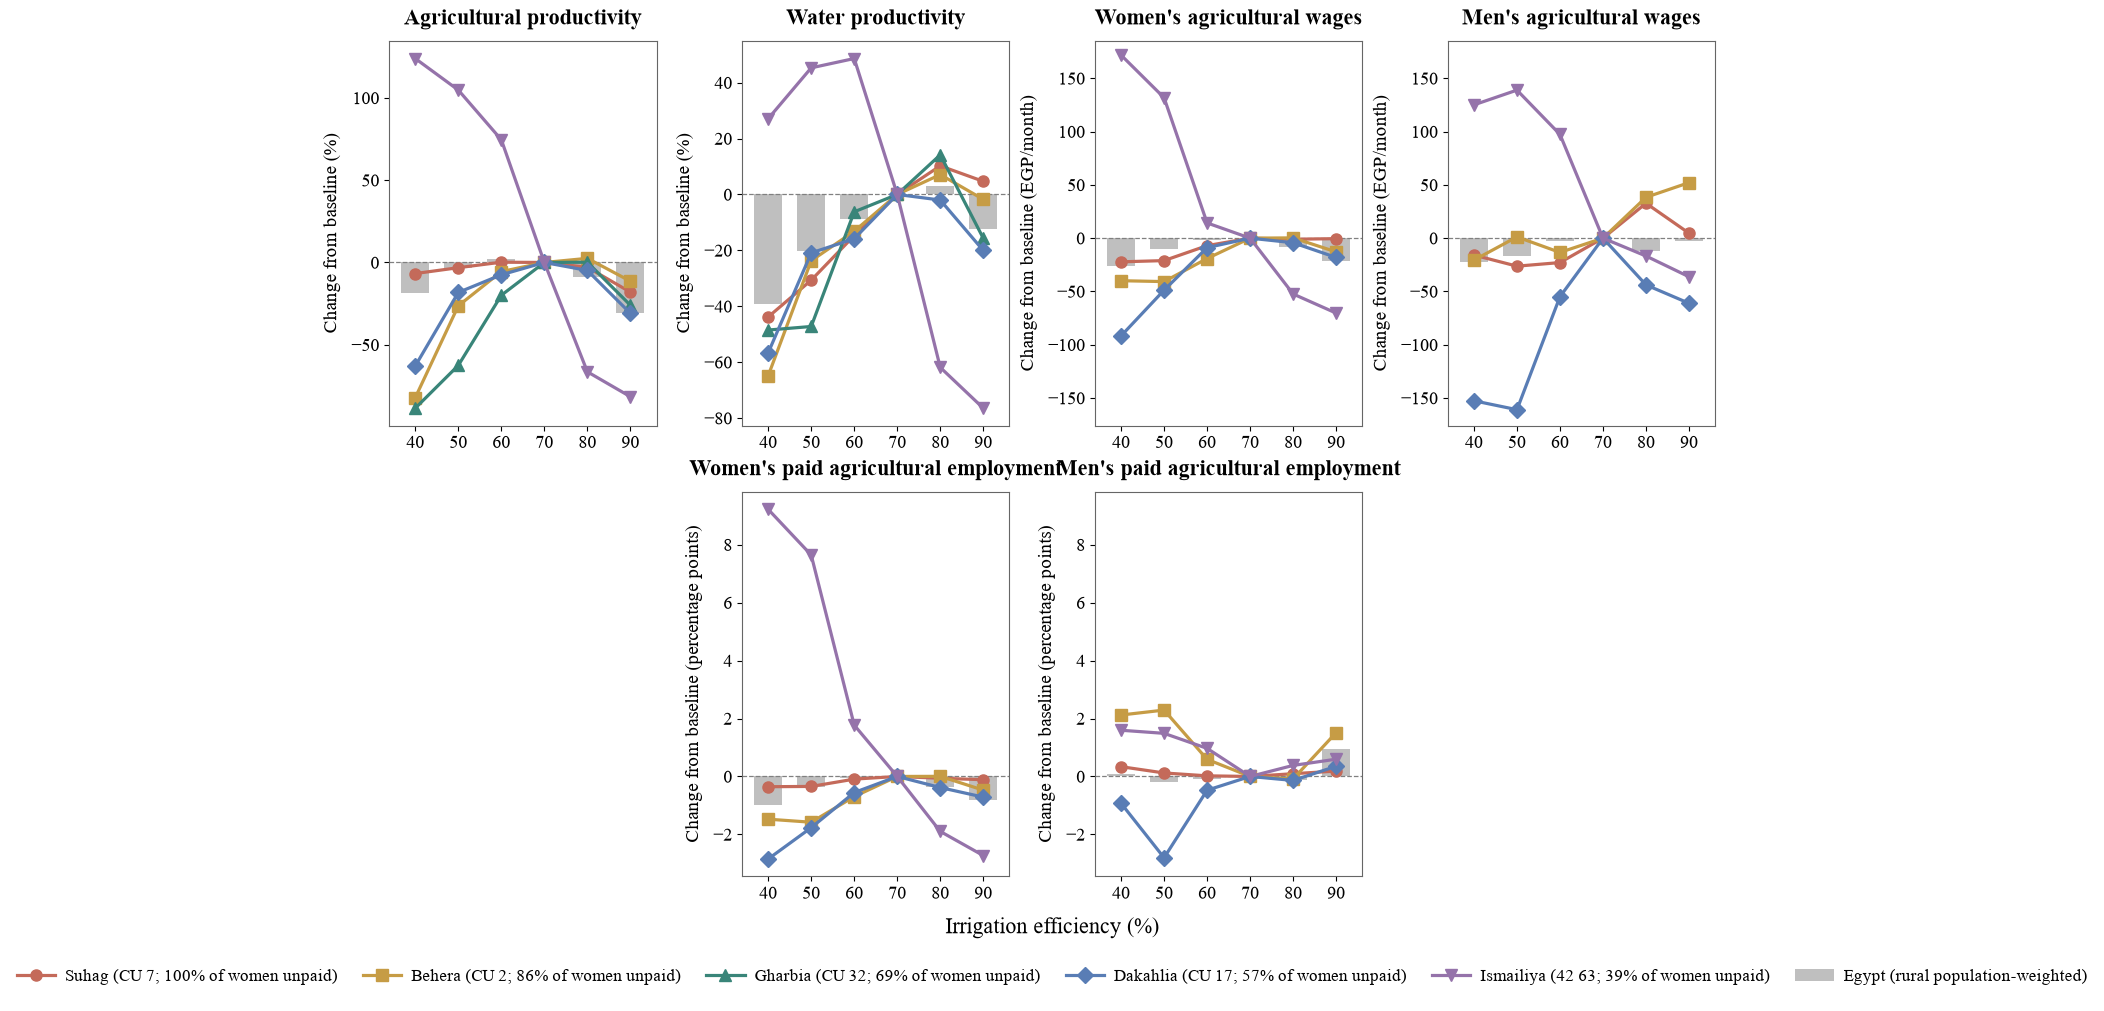

Saved: c:\Users\hermawan\OneDrive - Stichting Deltares\PhD\Egypt_ERF_data\figures\scenario_plot_multiple_locations_6panels.png


In [40]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Font settings
plt.rcParams.update({
    "font.family": "serif", "font.serif": ["Times New Roman"], "font.size": 14,
    "axes.titlesize": 16, "axes.labelsize": 14, "xtick.labelsize": 13,
    "ytick.labelsize": 13, "legend.fontsize": 12, "pdf.fonttype": 42, "ps.fonttype": 42,
})

# Settings
scenarios = ["40", "50", "60", "70", "80", "90"]
baseline = "70"

location_colors = ["#C46A5A", "#C69C45", "#398579", "#597DB5", "#9573AA", "#6F7645"]
location_markers = ["o", "s", "^", "D", "v", "P"]
location_column = "area"
weight_column = "rural_population"
min_baselines = {"agricultural_productivity": 0, "water_productivity": 0}

FIGURE_DIR = REPO_ROOT / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Add paid agricultural employment for each scenario to a copy of map_gdf
csv_path = Path(r"C:\Users\hermawan\OneDrive - Stichting Deltares\PhD\Egypt_ERF_data\Results\unemployment_rate.csv")
rate_df = pd.read_csv(csv_path, dtype={"scenario": str})
rate_df["scenario"] = rate_df["scenario"].str.strip()
rate_df["sex"] = rate_df["sex"].str.strip().str.lower()
rate_df = rate_df.loc[rate_df["scenario"].isin(scenarios) & rate_df["sex"].isin(["female", "male"])].copy()
rate_df["pct_paid"] = pd.to_numeric(rate_df["pct_paid"], errors="raise")
if not rate_df["pct_paid"].dropna().between(0, 100).all():
    raise ValueError("Expected pct_paid to be a percentage between 0 and 100.")

rates = rate_df.pivot(index="area", columns=["scenario", "sex"], values="pct_paid")
plot_gdf = map_gdf.copy()
for scenario in scenarios:
    for sex in ["female", "male"]:
        if (scenario, sex) not in rates.columns:
            raise ValueError(f"Missing pct_paid for {sex} in scenario {scenario}.")
        plot_gdf[f"employment_{sex}_{scenario}"] = plot_gdf[location_column].map(rates[(scenario, sex)])

panels = [
    ("agricultural_productivity", "Agricultural productivity", "productivity"),
    ("water_productivity", "Water productivity", "productivity"),
    ("female", "Women's agricultural wages", "wages"),
    ("male", "Men's agricultural wages", "wages"),
    ("employment_female", "Women's paid agricultural employment", "employment"),
    ("employment_male", "Men's paid agricultural employment", "employment"),
]

# Use the locations already selected in your notebook, in their original order
if not locations:
    raise ValueError("Add at least one location to the locations list.")
rows = {}
for location in locations:
    selected = plot_gdf.loc[plot_gdf[location_column] == location]
    if len(selected) != 1:
        raise ValueError(f"Expected one row for '{location}', found {len(selected)}. Check map_gdf['{location_column}'].")
    rows[location] = selected.iloc[0]

# Original four panels on top; two new panels centred underneath
x = [int(s) for s in scenarios]
fig = plt.figure(figsize=(20, 10), constrained_layout=True)
grid = fig.add_gridspec(4, 4, height_ratios=[4, 4, 0.35, 0.5])
axes = [fig.add_subplot(grid[0, i]) for i in range(4)]
axes.extend([fig.add_subplot(grid[1, 1]), fig.add_subplot(grid[1, 2])])

xlabel_ax = fig.add_subplot(grid[2, :])
xlabel_ax.set_axis_off()
xlabel_ax.text(0.5, 0.5, "Irrigation efficiency (%)", ha="center", va="center", fontsize=16, transform=xlabel_ax.transAxes)
legend_ax = fig.add_subplot(grid[3, :])
legend_ax.set_axis_off()

# Background bars: rural population-weighted averages
weights = np.asarray(plot_gdf[weight_column], dtype=float)
bar_width = min(np.diff(sorted(x))) * 0.65 if len(x) > 1 else 5

for ax, (var, title, group) in zip(axes, panels):
    baseline_values = np.asarray(plot_gdf[f"{var}_{baseline}"], dtype=float)
    scenario_values = np.column_stack([np.asarray(plot_gdf[f"{var}_{s}"], dtype=float) for s in scenarios])
    valid = np.isfinite(weights) & (weights > 0) & np.isfinite(baseline_values) & np.all(np.isfinite(scenario_values), axis=1)
    if not valid.any():
        raise ValueError(f"No areas with valid values and positive population for {var}.")

    baseline_mean = np.average(baseline_values[valid], weights=weights[valid])
    scenario_means = np.average(scenario_values[valid], axis=0, weights=weights[valid])
    overall_changes = scenario_means - baseline_mean

    if group == "productivity":
        if baseline_mean == 0 or abs(baseline_mean) < min_baselines[var]:
            overall_changes = np.zeros_like(scenario_means)
        else:
            overall_changes = overall_changes / baseline_mean * 100

    ax.bar(x, overall_changes, width=bar_width, color="#808080", alpha=0.5, edgecolor="none",
           zorder=1, label="Egypt (rural population-weighted)")

# Selected locations
for i, location in enumerate(locations):
    row = rows[location]
    color = location_colors[i % len(location_colors)]
    marker = location_markers[i % len(location_markers)]

    for ax, (var, title, group) in zip(axes, panels):
        values = np.array([row[f"{var}_{s}"] for s in scenarios], dtype=float)
        baseline_value = float(row[f"{var}_{baseline}"])
        change = values - baseline_value

        if group == "productivity":
            if baseline_value == 0 or abs(baseline_value) < min_baselines[var]:
                change = np.zeros_like(values)
            else:
                change = change / baseline_value * 100

        ax.plot(x, change, marker=marker, markersize=8, linewidth=2.3, color=color,
                markerfacecolor=color, markeredgecolor=color, markeredgewidth=1,
                label=legend_labels.get(location, location), zorder=3)

# Format panels
ylabels = {
    "productivity": "Change from baseline (%)",
    "wages": "Change from baseline (EGP/month)",
    "employment": "Change from baseline (percentage points)",
}
for ax, (_, title, group) in zip(axes, panels):
    ax.axhline(0, color="grey", linestyle="--", linewidth=0.9, zorder=2)
    ax.set_title(title, fontweight="bold", pad=12)
    ax.set_xticks(x)
    ax.set_ylabel(ylabels[group], labelpad=8)
    ax.set_axisbelow(True)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_color("#666666")
        spine.set_linewidth(0.8)

# Same y-axis range for women's and men's wages, and for their employment rates
for left, right in [(axes[2], axes[3]), (axes[4], axes[5])]:
    ymin = min(left.get_ylim()[0], right.get_ylim()[0])
    ymax = max(left.get_ylim()[1], right.get_ylim()[1])
    right.sharey(left)
    left.set_ylim(ymin, ymax)

# Shared legend on one line
handles, labels = axes[0].get_legend_handles_labels()
legend_ax.legend(handles, labels, loc="center", ncol=len(labels), frameon=False,
                 handlelength=2.3, columnspacing=1.5, handletextpad=0.6)

# Save and show
output_path = FIGURE_DIR / "scenario_plot_multiple_locations_6panels.png"
fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {output_path}")

Showing 39 command areas. 2 fall outside the y-axis range.


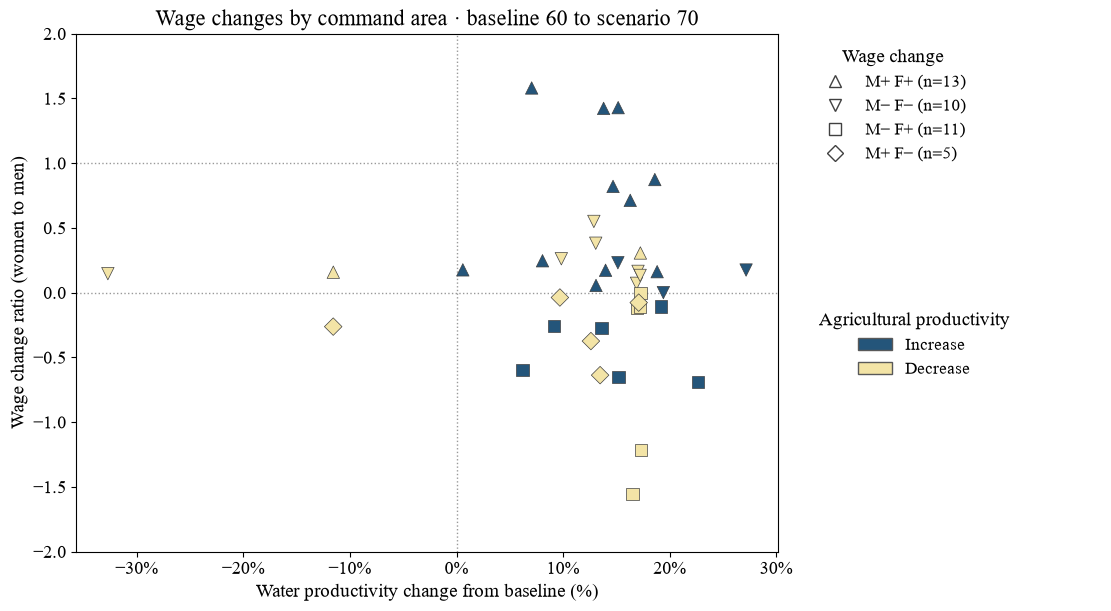

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator, PercentFormatter

# Settings
baseline = 60
scenario = 70
y_limits = (-2, 2)  # Use None for the full range
locations = []     # Use None for all labels, or ["Blk_Air_51"] to label 51

colour_key = {
    "Increase": "#24557A",     # Blue
    "Decrease": "#F3E4A6",     # Yellow
    "No change": "#FFFFFF",    # White
    "Unavailable": "#BDBDBD",  # Grey
}

# Find the baseline water-productivity column
water_cols = [
    col for col in map_gdf.columns
    if col.startswith("water_pro")
    and "no_salinity" not in col
    and col.endswith(f"_{baseline}")
]
if len(water_cols) != 1:
    raise ValueError(f"Expected one baseline water-productivity column, found {water_cols}")

water_prefix = water_cols[0].rsplit("_", 1)[0]

def scenario_change(prefix, *, percent=False):
    base = pd.to_numeric(map_gdf[f"{prefix}_{baseline}"])
    end = pd.to_numeric(map_gdf[f"{prefix}_{scenario}"])
    change = end - base
    if percent:
        return 100 * change / base.where(base.ne(0))
    return change

changes = pd.DataFrame({
    "area": map_gdf["area"],
    "water_pct": scenario_change(water_prefix, percent=True),
    "agri_pct": scenario_change("agricultural_productivity", percent=True),
    "women_change": scenario_change("female"),
    "men_change": scenario_change("male"),
}).replace([np.inf, -np.inf], np.nan)

# Keep areas with a valid x-coordinate and a wage direction for both groups
complete = changes.dropna(subset=["water_pct", "women_change", "men_change"])
nonzero = complete["women_change"].ne(0) & complete["men_change"].ne(0)
points = complete.loc[nonzero].copy()
points["wage_ratio"] = points["women_change"] / points["men_change"]

# Colour depends only on the sign of agricultural productivity change
points["agri_direction"] = "Unavailable"
points.loc[points["agri_pct"] > 0, "agri_direction"] = "Increase"
points.loc[points["agri_pct"] < 0, "agri_direction"] = "Decrease"
points.loc[points["agri_pct"] == 0, "agri_direction"] = "No change"
points["colour"] = points["agri_direction"].map(colour_key)

if y_limits is None:
    visible = points
else:
    ymin, ymax = y_limits
    if ymin >= ymax:
        raise ValueError("The lower y-axis limit must be smaller than the upper limit.")
    visible = points.loc[points["wage_ratio"].between(ymin, ymax)]

print(f"Showing {len(visible)} command areas. "
      f"{len(points) - len(visible)} fall outside the y-axis range.")

women_up = visible["women_change"].gt(0)
men_up = visible["men_change"].gt(0)
groups = [
    ("M+ F+",  men_up & women_up,  "^"),
    ("M− F−", ~men_up & ~women_up, "v"),
    ("M− F+", ~men_up & women_up,  "s"),
    ("M+ F−",  men_up & ~women_up, "D"),
]

fig = plt.figure(figsize=(11, 6), constrained_layout=True)
grid = fig.add_gridspec(2, 2, width_ratios=[3.3, 1.4])
ax = fig.add_subplot(grid[:, 0])
shape_ax = fig.add_subplot(grid[0, 1])
colour_ax = fig.add_subplot(grid[1, 1])
shape_ax.set_axis_off()
colour_ax.set_axis_off()

ax.axvline(0, color="0.6", linestyle=":", linewidth=1, zorder=0)
for y in (0, 1):
    ax.axhline(y, color="0.6", linestyle=":", linewidth=1, zorder=0)

shape_handles = []
for label, mask, marker in groups:
    group = visible.loc[mask]
    ax.scatter(
        group["water_pct"], group["wage_ratio"],
        marker=marker, s=80, c=group["colour"].tolist(),
        edgecolors="0.25", linewidths=0.5, zorder=2,
    )
    shape_handles.append(
        Line2D(
            [], [], linestyle="none", marker=marker, markersize=8,
            markerfacecolor="white", markeredgecolor="0.25",
            label=f"{label} (n={len(group)})",
        )
    )

selected = visible if locations is None else visible.loc[visible["area"].isin(locations)]
for row in selected.itertuples():
    ax.annotate(
        str(row.area).rsplit("_", 1)[-1],
        (row.water_pct, row.wage_ratio),
        xytext=(5, 4), textcoords="offset points", fontsize=9,
        fontweight="bold" if row.women_change > 0 and row.men_change > 0 else "normal",
    )

if y_limits is not None:
    ax.set_ylim(*y_limits)

ax.xaxis.set_major_locator(MaxNLocator(nbins=7, integer=True, min_n_ticks=1))
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
ax.set(
    xlabel="Water productivity change from baseline (%)",
    ylabel="Wage change ratio (women to men)",
    title=f"Wage changes by command area · baseline {baseline} to scenario {scenario}",
)

shape_ax.legend(
    handles=shape_handles, title="Wage change",
    loc="upper left", frameon=False,
)

used = set(visible["agri_direction"])
colour_handles = [
    Patch(facecolor=colour, edgecolor="0.35", label=label)
    for label, colour in colour_key.items()
    if label in used
]
if colour_handles:
    colour_ax.legend(
        handles=colour_handles, title="Agricultural productivity",
        loc="upper left", frameon=False,
    )

plt.show()
fig.savefig(FIGURE_DIR / "point.png", dpi=300, transparent=True, bbox_inches="tight")
plt.show()

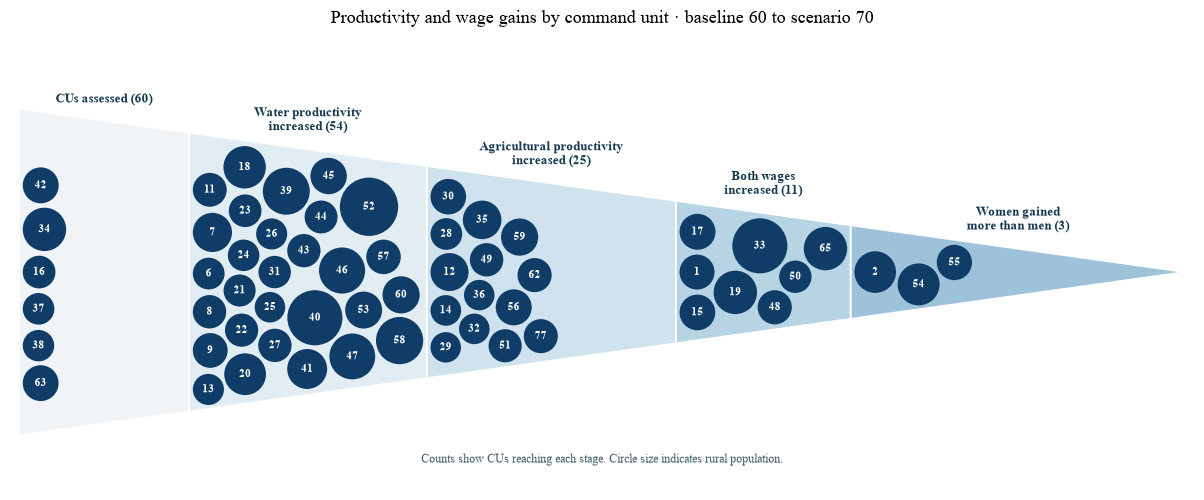

CUs assessed: 60 reached | 6 circles | CUs: 16, 34, 37, 38, 42, 63
Water productivity increased: 54 reached | 29 circles | CUs: 6, 7, 8, 9, 11, 13, 18, 20, 21, 22, 23, 24, 25, 26, 27, 31, 39, 40, 41, 43, 44, 45, 46, 47, 52, 53, 57, 58, 60
Agricultural productivity increased: 25 reached | 14 circles | CUs: 12, 14, 28, 29, 30, 32, 35, 36, 49, 51, 56, 59, 62, 77
Both wages increased: 11 reached | 8 circles | CUs: 1, 15, 17, 19, 33, 48, 50, 65
Women gained more than men: 3 reached | 3 circles | CUs: 2, 54, 55


In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Polygon

# ── Settings ──────────────────────────────────────────────────────────────
baseline = 60
scenario = 70
population_col = "rural_population"  # Set to your CU-level rural population count
ball_colour = "#103D68"
gap = 0.055                         # Small space between neighbouring circles

# ── Read the indicators from map_gdf ──────────────────────────────────────
if population_col not in map_gdf.columns:
    candidates = [
        col for col in map_gdf.columns
        if "pop" in col.lower() or "rural" in col.lower()
    ]
    raise KeyError(
        f"Column {population_col!r} was not found. Set population_col to the "
        f"rural population count in map_gdf. Possible columns: {candidates}"
    )

water_cols = [
    col for col in map_gdf.columns
    if col.startswith("water_pro")
    and "no_salinity" not in col
    and col.endswith(f"_{baseline}")
]
if len(water_cols) != 1:
    raise ValueError(f"Expected one baseline water-productivity column, found {water_cols}")

water_prefix = water_cols[0].rsplit("_", 1)[0]

def scenario_change(prefix, *, percent=False):
    base = pd.to_numeric(map_gdf[f"{prefix}_{baseline}"], errors="raise")
    end = pd.to_numeric(map_gdf[f"{prefix}_{scenario}"], errors="raise")
    change = end - base
    if percent:
        return 100 * change / base.where(base.ne(0))
    return change

data = pd.DataFrame({
    "area": map_gdf["area"],
    "water_pct": scenario_change(water_prefix, percent=True),
    "agri_pct": scenario_change("agricultural_productivity", percent=True),
    "women_change": scenario_change("female"),
    "men_change": scenario_change("male"),
    "population": pd.to_numeric(map_gdf[population_col], errors="raise"),
}).replace([np.inf, -np.inf], np.nan)

# Count each CU once, even if its geometry occupies multiple rows.
data = data.dropna(subset=["area"]).drop_duplicates().copy()
if data["area"].duplicated().any():
    duplicates = data.loc[data["area"].duplicated(keep=False), "area"].unique()
    raise ValueError(f"Conflicting values for these command units: {duplicates.tolist()}")
if data["population"].lt(0).any():
    raise ValueError("Rural population counts must be nonnegative.")

data["unit"] = data["area"].astype(str).str.rsplit("_", n=1).str[-1]
data["sort_id"] = pd.to_numeric(data["unit"], errors="coerce")
data = data.sort_values(["sort_id", "area"])

# ── Five cumulative stages ────────────────────────────────────────────────
assessed = data.loc[data["water_pct"].notna()]
water_up = assessed.loc[assessed["water_pct"].gt(0)]
agri_up = water_up.loc[water_up["agri_pct"].gt(0)]

both_up = agri_up.loc[
    agri_up["women_change"].gt(0) & agri_up["men_change"].gt(0)
]

# Both wages have already risen. Compare gains in the original wage units.
women_gained_more = both_up.loc[
    both_up["women_change"].gt(both_up["men_change"])
]

stages = [
    ("CUs assessed", assessed),
    ("Water productivity\nincreased", water_up),
    ("Agricultural productivity\nincreased", agri_up),
    ("Both wages\nincreased", both_up),
    ("Women gained\nmore than men", women_gained_more),
]

# Draw each CU only in the last stage it reached.
groups = []
for i, (_, reached) in enumerate(stages):
    shown = reached
    if i + 1 < len(stages):
        next_ids = stages[i + 1][1]["area"]
        shown = reached.loc[~reached["area"].isin(next_ids)]
    groups.append(shown.copy())

assert sum(len(group) for group in groups) == len(assessed)

# ── Population-sized circles ──────────────────────────────────────────────
# Circle area increases linearly with population above a small minimum
# that keeps the white CU numbers readable.
min_radius, max_radius = 0.25, 0.48
largest_pop = assessed["population"].max()

for group in groups:
    group["missing_pop"] = group["population"].isna()
    group["radius"] = min_radius
    if pd.notna(largest_pop) and largest_pop > 0:
        share = group["population"].fillna(0) / largest_pop
        group["radius"] = np.sqrt(
            min_radius**2 + share * (max_radius**2 - min_radius**2)
        )

# ── Pack the circles inside a shallow, horizontal triangle ────────────────
slope = 0.14
edge_factor = np.sqrt(1 + slope**2)
edge_pad = 0.06
heading_widths = [2.8, 3.6, 4.1, 2.8, 3.4]
fills = ["#F0F4F6", "#E2EDF3", "#CFE2ED", "#B7D4E5", "#9DC2D9"]

def pack_triangle(length):
    sections = []
    left = 0.0

    for group, min_width in zip(groups, heading_widths):
        placed = []
        right = left + min_width

        for item in group.itertuples():
            radius = item.radius
            first_x = left + edge_pad + radius
            clearance = (radius + edge_pad) * edge_factor
            ymax = slope * (length - first_x) - clearance
            if ymax < 0:
                return None

            # Find the leftmost free position, testing centre positions first.
            ys = np.linspace(-ymax, ymax, max(3, int(2 * ymax / 0.05) + 1))
            best = None

            for y in sorted(ys, key=abs):
                blocked = []
                for px, py, previous_radius, _, _ in placed:
                    distance = radius + previous_radius + gap
                    dy = abs(y - py)
                    if dy < distance:
                        dx = np.sqrt(distance**2 - dy**2)
                        blocked.append((px - dx, px + dx))

                x = first_x
                for lo, hi in sorted(blocked):
                    if lo < x < hi:
                        x = hi

                if abs(y) + clearance > slope * (length - x):
                    continue
                if best is None or x < best[0]:
                    best = (x, y)

            if best is None:
                return None

            x, y = best
            placed.append((x, y, radius, item.unit, item.missing_pop))
            right = max(right, x + radius + edge_pad)

        if right > length:
            return None

        sections.append((left, right, placed))
        left = right

    return sections

length = sum(heading_widths)
sections = pack_triangle(length)
while sections is None:
    length += 0.5
    sections = pack_triangle(length)

# ── Draw ──────────────────────────────────────────────────────────────────
half_height = slope * length
fig_width = max(12, length * 0.53)
fig_height = (2 * half_height + 2.5) * fig_width / length

fig, ax = plt.subplots(figsize=(fig_width, fig_height))
ax.set_aspect("equal")
ax.set_axis_off()
ax.set_xlim(-0.15, length + 0.15)
ax.set_ylim(-half_height - 0.9, half_height + 1.3)

for i, (left, right, placed) in enumerate(sections):
    end = length if i == len(sections) - 1 else right
    h_left = slope * (length - left)
    h_right = slope * (length - end)

    ax.add_patch(Polygon(
        [(left, h_left), (end, h_right), (end, -h_right), (left, -h_left)],
        closed=True, facecolor=fills[i], edgecolor="white", linewidth=1.4,
    ))

    heading, reached = stages[i]
    middle = (left + end) / 2
    ax.text(
        middle, slope * (length - middle) + 0.25,
        f"{heading} ({len(reached)})",
        ha="center", va="bottom",
        fontsize=9, fontweight="bold", color="#163950",
    )

    for x, y, radius, unit, missing_pop in placed:
        ax.add_patch(Circle(
            (x, y), radius,
            facecolor="#788793" if missing_pop else ball_colour,
            edgecolor="none",
        ))
        ax.text(
            x, y, unit,
            ha="center", va="center",
            fontsize=8, fontweight="bold", color="white",
        )

note = "Counts show CUs reaching each stage. Circle size indicates rural population."
if assessed["population"].isna().any():
    note += " Grey indicates missing population."

ax.text(
    length / 2, -half_height - 0.4, note,
    ha="center", va="center", fontsize=8.5, color="#425D6B",
)
ax.set_title(
    f"Productivity and wage gains by command unit · baseline {baseline} to scenario {scenario}",
    fontsize=13, pad=5,
)

fig.tight_layout(pad=0.4)
# fig.savefig("command_unit_funnel.png", dpi=300, bbox_inches="tight")
plt.show()

# Check which CUs are represented by the circles in each section.
for (heading, reached), shown in zip(stages, groups):
    name = heading.replace("\n", " ")
    units = ", ".join(shown["unit"]) or "none"
    print(f"{name}: {len(reached)} reached | {len(shown)} circles | CUs: {units}")

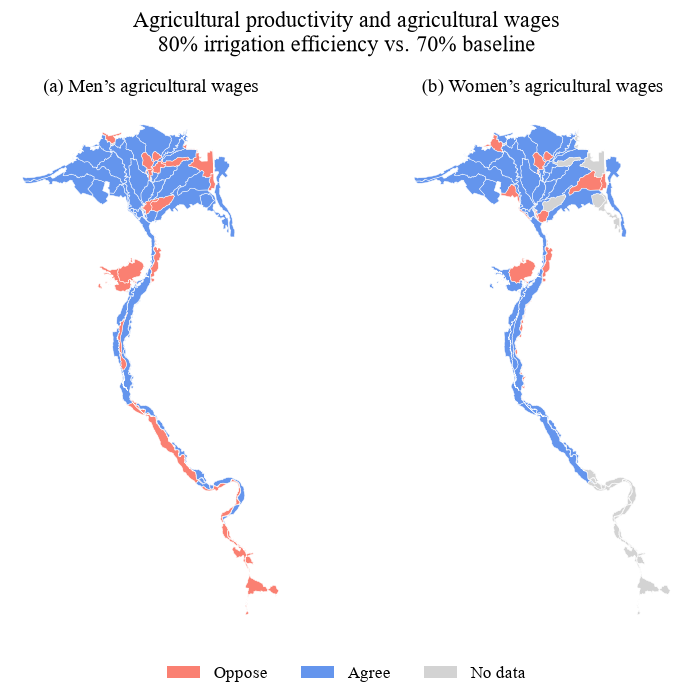

In [43]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

baseline, scenario = "70", "80"
gdf = map_gdf.to_crs(epsg=3857).copy()
colors = {"Oppose": "#FA8072", "Agree": "#6495ED", "No data": "#D3D3D3"}

# Agricultural productivity change is the same for both panels
prod_base = gdf[f"agricultural_productivity_{baseline}"]
prod_change = gdf[f"agricultural_productivity_{scenario}"] - prod_base

fig, axes = plt.subplots(1, 2, figsize=(8, 7), sharex=True, sharey=True)
panels = [("male", "(a) Men’s agricultural wages"), ("female", "(b) Women’s agricultural wages")]

for ax, (sex, title) in zip(axes, panels):
    wage_change = gdf[f"{sex}_{scenario}"] - gdf[f"{sex}_{baseline}"]
    valid = (prod_base > 0) & np.isfinite(prod_change) & np.isfinite(wage_change)

    column = f"agreement_{sex}"
    gdf[column] = "No data"
    gdf.loc[valid, column] = np.where(np.sign(prod_change[valid]) == np.sign(wage_change[valid]), "Agree", "Oppose")

    gdf.plot(ax=ax, color=gdf[column].map(colors), edgecolor="white", linewidth=0.35)
    ax.set_title(title, fontsize=14)
    ax.set_axis_off()

fig.suptitle(f"Agricultural productivity and agricultural wages\n{scenario}% irrigation efficiency vs. {baseline}% baseline", fontsize=16)
handles = [Patch(facecolor=color, label=label) for label, color in colors.items()]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, fontsize=12)
fig.subplots_adjust(top=0.85, bottom=0.08, left=0.02, right=0.98, wspace=0.04)

output_path = REPO_ROOT / "figures" / f"agricultural_productivity_male_female_wages_agreement_{scenario}_vs_{baseline}.png"
output_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()